# AV2 — Entrega de 27/11/2026: Seeds

Refino da regressão logística e análise dos erros na classificação de **Kama (1), Rosa (2) e Canadian (3)**. Execute as células em ordem no Google Colab ou em Jupyter.

O notebook lê `dados/dataset-seeds.txt` (arquivo original) ou `dados/dataset-seeds.csv` (cópia com cabeçalho). No Colab, envie um desses arquivos para `/content/` ou mantenha a pasta `dados/` junto ao notebook. Primeiro, separamos treino e teste; depois, escolhemos a regularização somente com o treino e avaliamos o modelo fixado no teste reservado.

## 1. Importação das bibliotecas

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## 2. Configuração de exibição

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42

## 3. Coleta e leitura dos dados

In [3]:
colunas = [
    "area", "perimetro", "compacidade", "comprimento_grao",
    "largura_grao", "coeficiente_assimetria", "comprimento_sulco", "classe",
]
candidatos = [
    Path("dados/dataset-seeds.txt"),
    Path("dados/dataset-seeds.csv"),
    Path("dataset-seeds.txt"),
    Path("dataset-seeds.csv"),
    Path("/content/dados/dataset-seeds.txt"),
    Path("/content/dados/dataset-seeds.csv"),
    Path("/content/dataset-seeds.txt"),
    Path("/content/dataset-seeds.csv"),
]
caminho_dados = next((p for p in candidatos if p.is_file()), None)
if caminho_dados is None:
    raise FileNotFoundError("Coloque dataset-seeds.txt ou dataset-seeds.csv em dados/ ou /content/.")

if caminho_dados.suffix == ".txt":
    # Original UCI: sem cabeçalho, com espaços e tabulações entre os valores.
    dados = pd.read_csv(caminho_dados, sep=r"\s+", header=None, names=colunas)
else:
    # CSV do projeto: cabeçalho, ponto e vírgula e ponto decimal.
    dados = pd.read_csv(caminho_dados, sep=";")
    if dados.columns.tolist() != colunas:
        raise ValueError("As colunas do CSV não correspondem ao esquema esperado.")
print(f"Arquivo: {caminho_dados} | dimensão inicial: {dados.shape}")

Arquivo: dados\dataset-seeds.txt | dimensão inicial: (210, 8)


In [4]:
display(dados.head())

,area,perimetro,compacidade,comprimento_grao,largura_grao,coeficiente_assimetria,comprimento_sulco,classe
0,15.26,14.84,0.871,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.881,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.905,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.895,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.903,5.658,3.562,1.355,5.175,1


## 4. Limpeza e verificação de consistência

In [5]:
# Conversão explícita: texto inesperado passa a ausente e entra na auditoria.
dados_numericos = dados.apply(pd.to_numeric, errors="coerce")
atributos = colunas[:-1]
auditoria = pd.DataFrame({
    "tipo": dados_numericos.dtypes.astype(str),
    "ausentes": dados_numericos.isna().sum(),
    "valores_unicos": dados_numericos.nunique(dropna=True),
})
print(f"Linhas duplicadas exatas: {dados_numericos.duplicated().sum()}")
print(f"Medidas infinitas: {np.isinf(dados_numericos[atributos].to_numpy()).sum()}")
display(auditoria)

Linhas duplicadas exatas: 0
Medidas infinitas: 0


,tipo,ausentes,valores_unicos
area,float64,0,193
perimetro,float64,0,170
compacidade,float64,0,186
comprimento_grao,float64,0,188
largura_grao,float64,0,184
coeficiente_assimetria,float64,0,207
comprimento_sulco,float64,0,148
classe,int64,0,3


In [6]:
# Primeiro, elimine registros incompletos; depois, duplicatas exatas.
sem_ausentes = dados_numericos.replace([np.inf, -np.inf], np.nan).dropna().copy()
sem_duplicatas = sem_ausentes.drop_duplicates().copy()
valores_validos = (
    sem_duplicatas["classe"].isin([1, 2, 3])
    & sem_duplicatas[atributos].gt(0).all(axis=1)
    & sem_duplicatas["compacidade"].between(0, 1)
)
dados_limpos = sem_duplicatas.loc[valores_validos].copy()
dados_limpos["classe"] = dados_limpos["classe"].astype(int)

resumo_limpeza = pd.Series({
    "linhas_originais": len(dados),
    "removidas_por_ausencia_texto_ou_infinito": len(dados) - len(sem_ausentes),
    "duplicatas_exatas_removidas": len(sem_ausentes) - len(sem_duplicatas),
    "removidas_por_valores_invalidos": (~valores_validos).sum(),
    "linhas_finais": len(dados_limpos),
}, name="quantidade")
display(resumo_limpeza.to_frame())
if dados_limpos.empty:
    raise ValueError("Nenhuma linha válida após a limpeza.")

,quantidade
linhas_originais,210
removidas_por_ausencia_texto_ou_infinito,0
duplicatas_exatas_removidas,0
removidas_por_valores_invalidos,0
linhas_finais,210


A auditoria verifica ausências, texto inesperado, infinitos, duplicatas, classes fora de 1–3, medidas não positivas e compacidade fora de 0–1. O arquivo fornecido não exige remoção nem imputação. Essa conferência prepara os dados para o refino e a avaliação abaixo.

## 5. Pré-processamento e separação do teste

In [7]:
X = dados_limpos[atributos].copy()
y = dados_limpos["classe"].copy()
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Treino: {X_treino.shape} | Teste reservado: {X_teste.shape}")
print("Classes no treino:", y_treino.value_counts().sort_index().to_dict())
print("Classes no teste:", y_teste.value_counts().sort_index().to_dict())

Treino: (168, 7) | Teste reservado: (42, 7)
Classes no treino: {1: 56, 2: 56, 3: 56}
Classes no teste: {1: 14, 2: 14, 3: 14}


A divisão estratificada preserva as três classes no treino e no teste. O refino e a seleção de atributos usam apenas o treino; dentro da validação cruzada, cada transformação é ajustada novamente em cada dobra. O teste será usado somente após a configuração do modelo estar definida.

## 6. Refino da regressão logística no treino

O modelo de partida é uma **regressão logística com quatro atributos**. Mantemos esse tipo de modelo, a divisão estratificada de **168 grãos de treino e 42 de teste**, e a semente 42. Nesta etapa, refinamos somente `C`, que controla a intensidade da regularização: quanto menor o valor, maior a penalidade sobre os coeficientes. A seleção de quatro atributos por ANOVA e a padronização continuam dentro do pipeline.

Comparamos `C = 0,01; 0,1; 1; 10; 100` por validação cruzada estratificada de cinco dobras. A métrica principal é o **F1 macro**, que dá o mesmo peso às três classes. Nenhuma previsão do conjunto de teste participa desta escolha.

In [8]:
# Definimos o mesmo pipeline para cada valor de C; seleção e escala são refeitas em cada dobra.
from joblib import dump
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import cross_validate

VALORES_C = (0.01, 0.1, 1.0, 10.0, 100.0)

def construir_pipeline(c):
    return Pipeline([
        ("selecao", SelectKBest(score_func=f_classif, k=4)),
        ("padronizacao", StandardScaler()),
        ("classificador", LogisticRegression(C=c, max_iter=2000, random_state=RANDOM_STATE)),
    ])

print("Valores de C:", VALORES_C)
print("Treino:", len(X_treino), "grãos | Teste reservado:", len(X_teste), "grãos")

Valores de C: (0.01, 0.1, 1.0, 10.0, 100.0)
Treino: 168 grãos | Teste reservado: 42 grãos


In [9]:
# Comparamos os cinco valores de C apenas nos 168 grãos de treino.
validacao_27_11 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
linhas_refino_27_11 = []

for c in VALORES_C:
    notas = cross_validate(
        construir_pipeline(c), X_treino, y_treino, cv=validacao_27_11,
        scoring={"f1_macro": "f1_macro", "acuracia": "accuracy"},
        return_train_score=True, n_jobs=1,
    )
    linhas_refino_27_11.append({
        "C": c,
        "f1_macro_cv": notas["test_f1_macro"].mean(),
        "desvio_f1_cv": notas["test_f1_macro"].std(ddof=1),
        "acuracia_cv": notas["test_acuracia"].mean(),
        "acuracia_treino_cv": notas["train_acuracia"].mean(),
    })

comparacao_c_27_11 = pd.DataFrame(linhas_refino_27_11).sort_values(
    ["f1_macro_cv", "acuracia_cv", "C"], ascending=[False, False, True]
)
with pd.option_context("display.precision", 4):
    display(comparacao_c_27_11.round(4))

,C,f1_macro_cv,desvio_f1_cv,acuracia_cv,acuracia_treino_cv
3,10.00,0.9462,0.0398,0.9465,0.9628
4,100.00,0.9402,0.0486,0.9405,0.9688
2,1.00,0.9276,0.0478,0.9287,0.9375
1,0.10,0.9097,0.0570,0.9111,0.9182
0,0.01,0.8822,0.0301,0.8868,0.8988


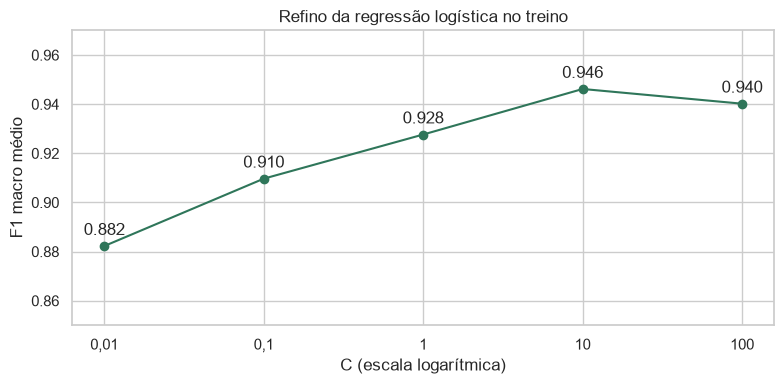

In [10]:
# Mostramos como o F1 macro de validação varia com a regularização.
dados_grafico_27_11 = comparacao_c_27_11.sort_values("C")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(dados_grafico_27_11["C"], dados_grafico_27_11["f1_macro_cv"], marker="o", color="#2F765A")
ax.set_xscale("log")
ax.set_xticks(VALORES_C, labels=["0,01", "0,1", "1", "10", "100"])
ax.set(xlabel="C (escala logarítmica)", ylabel="F1 macro médio", title="Refino da regressão logística no treino")
ax.set_ylim(0.85, 0.97)
for c, valor in zip(dados_grafico_27_11["C"], dados_grafico_27_11["f1_macro_cv"]):
    ax.annotate(f"{valor:.3f}", (c, valor), xytext=(0, 8), textcoords="offset points", ha="center")
plt.tight_layout()
plt.show()

### 6.1 Configuração escolhida antes de abrir o teste

Na execução registrada, `C=10` teve o maior F1 macro médio na validação: **0,9462**. Pela regra de 1 erro padrão, `C=10` e `C=100` ficaram dentro do limite de **0,9284**; escolhemos `C=10`, que mantém regularização mais forte entre os dois. Essa comparação serve para escolher o ajuste e pode ser otimista como estimativa de desempenho em dados novos.

In [11]:
# Fixamos C pela validação e só então treinamos o pipeline com todo o conjunto de treino.
melhor_cv_27_11 = comparacao_c_27_11.iloc[0]
limiar_27_11 = melhor_cv_27_11["f1_macro_cv"] - melhor_cv_27_11["desvio_f1_cv"] / np.sqrt(5)
elegiveis_27_11 = comparacao_c_27_11.loc[comparacao_c_27_11["f1_macro_cv"] >= limiar_27_11]
C_ESCOLHIDO = float(elegiveis_27_11.sort_values("C").iloc[0]["C"])

modelo_27_11 = construir_pipeline(C_ESCOLHIDO).fit(X_treino, y_treino)
atributos_finais_27_11 = X_treino.columns[modelo_27_11.named_steps["selecao"].get_support()].tolist()
Path("modelos").mkdir(exist_ok=True)
caminho_modelo_27_11 = Path("modelos/modelo_27-11.joblib")
dump(modelo_27_11, caminho_modelo_27_11)

print(f"Limiar de 1 erro padrão: {limiar_27_11:.4f}")
print(f"C fixado antes do teste: {C_ESCOLHIDO:g}")
print("Atributos selecionados:", atributos_finais_27_11)
print("Pipeline salvo em:", caminho_modelo_27_11)

Limiar de 1 erro padrão: 0.9284
C fixado antes do teste: 10
Atributos selecionados: ['area', 'perimetro', 'largura_grao', 'comprimento_sulco']
Pipeline salvo em: modelos\modelo_27-11.joblib


## 7. Avaliação final no teste reservado

Agora que o pipeline está fixado, fazemos **uma avaliação final** nos 42 grãos reservados. A acurácia mostra a proporção total de acertos; o F1 macro resume o desempenho das três classes com pesos iguais. A matriz de confusão mostra quais variedades foram confundidas. Os resultados do teste não serão usados para alterar o modelo.

In [12]:
# Aplicamos o modelo já fixado ao teste uma vez e calculamos métricas gerais e por classe.
classes_27_11 = [1, 2, 3]
nomes_classes_27_11 = {1: "Kama", 2: "Rosa", 3: "Canadian"}
previsoes_teste_27_11 = modelo_27_11.predict(X_teste)
probabilidades_teste_27_11 = modelo_27_11.predict_proba(X_teste)

acuracia_teste_27_11 = accuracy_score(y_teste, previsoes_teste_27_11)
f1_macro_teste_27_11 = f1_score(y_teste, previsoes_teste_27_11, average="macro")
matriz_27_11 = confusion_matrix(y_teste, previsoes_teste_27_11, labels=classes_27_11)
relatorio_27_11 = classification_report(
    y_teste, previsoes_teste_27_11, labels=classes_27_11,
    output_dict=True, zero_division=0,
)

print(f"Acurácia no teste: {acuracia_teste_27_11:.4f} ({(previsoes_teste_27_11 == y_teste).sum()}/{len(y_teste)})")
print(f"F1 macro no teste: {f1_macro_teste_27_11:.4f}")
print(f"Referência de uma classe: {14 / 42:.4f} (14/42)")

metricas_por_classe_27_11 = pd.DataFrame({
    nomes_classes_27_11[classe]: relatorio_27_11[str(classe)] for classe in classes_27_11
}).T[["precision", "recall", "f1-score", "support"]]
with pd.option_context("display.precision", 4):
    display(metricas_por_classe_27_11.round(4))

Acurácia no teste: 0.9048 (38/42)
F1 macro no teste: 0.9007
Referência de uma classe: 0.3333 (14/42)


,precision,recall,f1-score,support
Kama,1.0000,0.7143,0.8333,14.0
Rosa,0.9333,1.0000,0.9655,14.0
Canadian,0.8235,1.0000,0.9032,14.0


,Previsto: Kama,Previsto: Rosa,Previsto: Canadian
Real: Kama,10,1,3
Real: Rosa,0,14,0
Real: Canadian,0,0,14


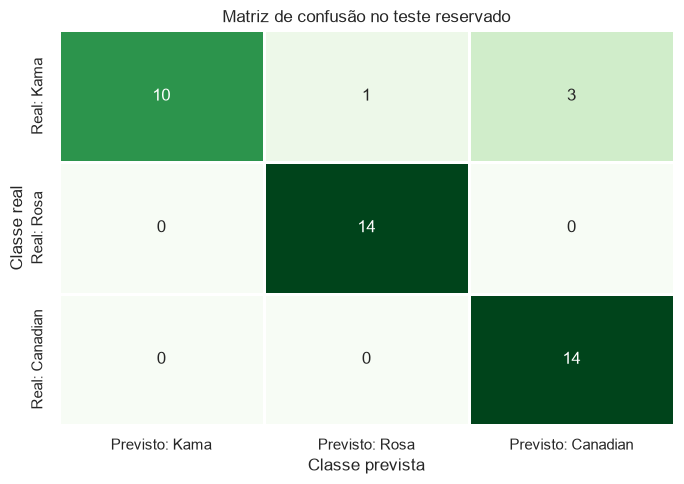

In [13]:
# Lemos a matriz por linhas reais e colunas previstas para localizar as confusões.
matriz_df_27_11 = pd.DataFrame(
    matriz_27_11,
    index=[f"Real: {nomes_classes_27_11[c]}" for c in classes_27_11],
    columns=[f"Previsto: {nomes_classes_27_11[c]}" for c in classes_27_11],
)
display(matriz_df_27_11)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(matriz_df_27_11, annot=True, fmt="d", cmap="Greens", cbar=False, linewidths=1, ax=ax)
ax.set_title("Matriz de confusão no teste reservado")
ax.set(xlabel="Classe prevista", ylabel="Classe real")
plt.tight_layout()
plt.show()

## 8. Análise dos erros

Examinamos as linhas incorretas **depois** da avaliação final. A tabela abaixo mostra a linha do arquivo bruto, a classe real, a classe prevista e as quatro medidas usadas pelo modelo. O escore da classe prevista vem de `predict_proba`; como não fizemos calibração, ele não deve ser interpretado como certeza de acerto.

In [14]:
# Localizamos os exemplos incorretos sem ajustar novamente o classificador.
previsoes_df_27_11 = pd.DataFrame({
    "linha_original": X_teste.index.to_numpy() + 1,
    "classe_real": y_teste.map(nomes_classes_27_11).to_numpy(),
    "classe_prevista": pd.Series(previsoes_teste_27_11, index=X_teste.index).map(nomes_classes_27_11).to_numpy(),
    "escore_previsto": probabilidades_teste_27_11.max(axis=1),
}, index=X_teste.index)
previsoes_df_27_11 = pd.concat([previsoes_df_27_11, X_teste[atributos_finais_27_11]], axis=1)
erros_27_11 = previsoes_df_27_11.loc[
    previsoes_df_27_11["classe_real"] != previsoes_df_27_11["classe_prevista"]
].sort_values("linha_original")
with pd.option_context("display.precision", 3):
    display(erros_27_11.reset_index(drop=True).round(3))
print("Total de erros:", len(erros_27_11))

,linha_original,classe_real,classe_prevista,escore_previsto,area,perimetro,largura_grao,comprimento_sulco
0,24,Kama,Canadian,0.968,12.08,13.23,2.936,4.961
1,38,Kama,Rosa,0.808,17.08,15.38,3.683,5.484
2,61,Kama,Canadian,0.937,11.42,12.86,2.850,4.607
3,62,Kama,Canadian,0.997,11.23,12.63,2.879,4.703


Total de erros: 4


In [15]:
# Comparamos os erros com medianas calculadas apenas no treino; é um diagnóstico descritivo.
medianas_treino_27_11 = X_treino.assign(classe=y_treino).groupby("classe")[
    ["area", "largura_grao"]
].median()
medianas_treino_27_11.index = medianas_treino_27_11.index.map(nomes_classes_27_11)
display(medianas_treino_27_11.round(3))

,area,largura_grao
classe,,
Kama,14.405,3.258
Rosa,18.785,3.694
Canadian,11.825,2.828


**Conclusão:** o modelo com `C=10` acertou **38 de 42 grãos (90,48%)**, com **F1 macro de 0,9007**. A regra simples que sempre prevê uma única classe acertaria **14 de 42 (33,33%)** neste teste equilibrado. Os **quatro erros foram grãos Kama**: três previstos como Canadian e um como Rosa; o recall de Kama foi **71,43%**. As áreas e larguras dos casos incorretos se aproximam dos valores centrais das classes previstas no treino, mas isso descreve uma associação, não demonstra a causa dos erros. Como o teste tem apenas 42 grãos de uma única divisão, o resultado não garante o mesmo desempenho em outras origens. Depois de consultar o teste, não fazemos novo ajuste do modelo neste notebook.